# 3D. Forecasting Regressor Models (3 h ahead)

This notebook trains and evaluates five regressors that **forecast** the DC power of a 15-minute slot 3 h after the latest observed slot, on the `forecast_3h` dataset exported by notebook 2 (pipeline 8C): Linear Regression, Decision Tree, Random Forest, MLP and XGBoost. The features are known at forecast time (recent power and irradiance, ambient temperature, power at the same time yesterday, and the calendar of the target time).

Section 3D.0 scores two baselines first: persistence (the power stays as it is now) and same time yesterday. A forecasting model is only useful if it beats them; the skill score `1 − RMSE / RMSE_persistence` in the summary measures by how much. Each model then has its own block with four steps: cross-validation, training, evaluation and metrics.

In [1]:
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "data" / "features").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the thesis project root.")

# Select the system, target and feature configuration.
SYSTEM_ID = 4
TARGET = "dc_power__314"
CONFIG = "forecast_3h"

METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
EXPERIMENTS_DIR = PROJECT_ROOT / "artifacts" / "experiments"
MODELS_DIR = PROJECT_ROOT / "artifacts" / "models"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Configuration: {CONFIG}")

Project root: /home/raul/Desktop/solar-data-all/thesis
Configuration: forecast_3h


## Setup: load the train/test data

Read the `forecast_3h` row of the configuration summary written by notebook 2, then load its CSVs with the target slot's `datetime` as the index. The features are already MinMax-scaled; the target is in watts. `baselines_test` holds the unscaled baseline forecasts for the test rows. If the data does not exist yet, this cell stops with a message naming the notebook 2 pipeline to run (8C).

In [2]:
CONFIG_SUMMARY_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_feature_configs.csv"
config_summary = pd.read_csv(CONFIG_SUMMARY_PATH, index_col="config")
if CONFIG not in config_summary.index:
    raise FileNotFoundError(
        f"No '{CONFIG}' data in {CONFIG_SUMMARY_PATH.name}; "
        f"run pipeline 8C in notebook 2 first."
    )

group_name = config_summary.loc[CONFIG, "group_name"]
feature_directory = PROJECT_ROOT / "data" / "features" / group_name


def load_partition(part):
    """Load one exported partition with its datetime index."""
    return pd.read_csv(feature_directory / f"{part}_{group_name}.csv",
                       index_col="datetime", parse_dates=True)


X_train, X_test = load_partition("X_train"), load_partition("X_test")
y_train, y_test = load_partition("y_train")[TARGET], load_partition("y_test")[TARGET]
baselines_test = load_partition("baselines_test")

assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert baselines_test.index.equals(y_test.index)
assert not any(part.isna().any().any() for part in (X_train, X_test, y_train.to_frame(), y_test.to_frame()))
assert X_train.index.max() < X_test.index.min()

FEATURES = list(X_train.columns)
print(f"Features: {FEATURES}")
display(pd.DataFrame(
    {name: {"rows": len(part), "start": part.index.min(), "end": part.index.max()}
     for name, part in {"train": X_train, "test": X_test}.items()}
).T)

Features: ['power_t', 'power_t-15min', 'power_t-1h', 'power_t-24h', 'irradiance_t', 'irradiance_t-1h', 'irradiance_t-24h', 'ambient_temp_t', 'power_target-24h', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']


,rows,start,end
train,93812,2007-08-27 06:00:00,2016-01-21 08:45:00
test,20884,2016-01-21 09:00:00,2023-01-31 16:45:00


## Setup: shared evaluation

Every model block below uses the same evaluation:

- **Cross-validation:** `TimeSeriesSplit` with `N_SPLITS` expanding folds. Each fold trains on earlier data and validates on the block that follows, so no future data leaks into training. The forecasting data have one row per 15-minute slot (about 94k training rows), so CV uses every training row (`CV_SUBSAMPLE_STEP = 1`). It is repeated for every seed in `SEEDS`, so the spread covers both time periods and model randomness.
- **Final model:** fitted on the full training set with the first seed, then scored on the full test set.
- **Metrics:** MAE, RMSE and R², all in watts.

Results are kept in dictionaries keyed by model name, so re-running a block replaces its results instead of duplicating them.

In [3]:
# Cross-validation settings shared by every model.
SEEDS = [0, 1, 2]
N_SPLITS = 5
CV_SUBSAMPLE_STEP = 1

X_cv = X_train.iloc[::CV_SUBSAMPLE_STEP]
y_cv = y_train.iloc[::CV_SUBSAMPLE_STEP]
cv_splitter = TimeSeriesSplit(n_splits=N_SPLITS)

cv_results, test_results, test_predictions = {}, {}, {}


def regression_metrics(y_true, y_pred):
    """MAE, RMSE and R² in the target's units (W)."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    }


def run_cv(make_model, seeds):
    """Time-series CV on the subsample: one row per seed and fold."""
    rows = []
    for seed in seeds:
        for fold, (fit_rows, val_rows) in enumerate(cv_splitter.split(X_cv), start=1):
            model = make_model(seed)
            start = time.perf_counter()
            model.fit(X_cv.iloc[fit_rows], y_cv.iloc[fit_rows])
            fit_seconds = time.perf_counter() - start
            scores = regression_metrics(y_cv.iloc[val_rows], model.predict(X_cv.iloc[val_rows]))
            rows.append({"seed": seed, "fold": fold, "fit_rows": len(fit_rows),
                         "val_rows": len(val_rows), **scores, "fit_seconds": fit_seconds})
    return pd.DataFrame(rows)


def cv_summary(cv_table):
    """Mean and standard deviation of the CV metrics over all seeds and folds."""
    return cv_table[["MAE", "RMSE", "R2"]].agg(["mean", "std"])


def fit_and_time(model, X, y):
    """Fit a model and return the fit time in seconds."""
    start = time.perf_counter()
    model.fit(X, y)
    return time.perf_counter() - start


def predict_and_time(model, X):
    """Predict and return the predictions with the prediction time in seconds."""
    start = time.perf_counter()
    predictions = model.predict(X)
    return predictions, time.perf_counter() - start


def summarize_model(cv_table, train_pred, test_pred, fit_seconds, predict_seconds, model_path):
    """One comparison row: CV mean/std, train and test metrics, timing and model size."""
    stats = cv_summary(cv_table)
    row = {f"cv_{metric}_{stat}": stats.loc[stat, metric]
           for metric in ("MAE", "RMSE", "R2") for stat in ("mean", "std")}
    row.update({f"train_{k}": v for k, v in regression_metrics(y_train, train_pred).items()})
    row.update({f"test_{k}": v for k, v in regression_metrics(y_test, test_pred).items()})
    row.update({"cv_runs": len(cv_table), "fit_seconds": fit_seconds,
                "predict_seconds": predict_seconds,
                "model_size_kb": model_path.stat().st_size / 1024})
    return row


print(f"CV subsample: {len(X_cv):,} of {len(X_train):,} training rows "
      f"({N_SPLITS} folds x {len(SEEDS)} seeds)")

CV subsample: 93,812 of 93,812 training rows (5 folds x 3 seeds)


## 3D.0 Baselines

Two forecasts that need no training, scored on the test rows:

- **Persistence**: the power of the target slot equals the power of the latest observed slot (3 h earlier).
- **Same time yesterday**: the power of the target slot equals the power of the same slot 24 h earlier.

They are added to the comparison like the models (without CV, training time or size); every model's skill is measured against persistence.

In [4]:
for baseline, column in (("Persistence", "persistence"), ("Same time yesterday", "same_time_yesterday")):
    test_predictions[baseline] = baselines_test[column].to_numpy()
    test_results[baseline] = {f"test_{k}": v for k, v in
                              regression_metrics(y_test, baselines_test[column]).items()}

display(pd.DataFrame(test_results).T.round(3))

,test_MAE,test_RMSE,test_R2
Persistence,314.547,397.458,-0.533
Same time yesterday,173.330,278.944,0.245


## 3D.1 Linear Regression

The baseline: an ordinary least-squares fit of the target on the features. It has no hyperparameters and no randomness, so cross-validation runs with a single seed; its spread comes from the folds only.

### 3D.1.1 Cross-validation (Linear Regression)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [5]:
def make_linear_regression(seed):
    """LinearRegression has no randomness; the seed is ignored."""
    return LinearRegression()


cv_results["Linear Regression"] = run_cv(make_linear_regression, seeds=SEEDS[:1])
display(cv_results["Linear Regression"].round(3))
display(cv_summary(cv_results["Linear Regression"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,15637,15635,165.098,212.501,0.554,0.005
1,0,2,31272,15635,155.030,200.701,0.596,0.009
2,0,3,46907,15635,169.815,213.487,0.543,0.010
3,0,4,62542,15635,170.758,218.387,0.495,0.013
4,0,5,78177,15635,162.465,204.892,0.561,0.016


,MAE,RMSE,R2
mean,164.633,209.994,0.550
std,6.354,7.094,0.036


### 3D.1.2 Training (Linear Regression)

Fit the final model on the full training set with the first seed and record the fit time.

In [6]:
lr_model = make_linear_regression(SEEDS[0])
lr_fit_seconds = fit_and_time(lr_model, X_train, y_train)
print(f"Linear Regression: fitted on {len(X_train):,} rows in {lr_fit_seconds:.1f} s")

Linear Regression: fitted on 93,812 rows in 0.0 s


### 3D.1.3 Evaluation (Linear Regression)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [7]:
lr_train_pred, _ = predict_and_time(lr_model, X_train)
lr_test_pred, lr_predict_seconds = predict_and_time(lr_model, X_test)
test_predictions["Linear Regression"] = lr_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, lr_train_pred),
                      "test": regression_metrics(y_test, lr_test_pred)}).T.round(3))
print(f"Test prediction time: {lr_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,169.979,211.303,0.559
test,161.610,204.472,0.594


Test prediction time: 0.00 s for 20,884 rows


### 3D.1.4 Metrics (Linear Regression)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [8]:
lr_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_linear_regression.pkl"
with lr_model_path.open("wb") as model_file:
    pickle.dump(lr_model, model_file)

test_results["Linear Regression"] = summarize_model(cv_results["Linear Regression"], lr_train_pred, lr_test_pred,
                                         lr_fit_seconds, lr_predict_seconds, lr_model_path)
display(pd.Series(test_results["Linear Regression"], name="Linear Regression").to_frame().round(3))
print(f"Model saved to: {lr_model_path}")

,Linear Regression
cv_MAE_mean,164.633
cv_MAE_std,6.354
cv_RMSE_mean,209.994
cv_RMSE_std,7.094
cv_R2_mean,0.550
cv_R2_std,0.036
train_MAE,169.979
train_RMSE,211.303
train_R2,0.559
test_MAE,161.610


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_forecast_3h_linear_regression.pkl


## 3D.2 Decision Tree

A single regression tree. `DT_MAX_DEPTH` and `DT_MIN_SAMPLES_LEAF` limit its size; an unlimited tree on more than a million rows would memorise noise and grow very large.

### 3D.2.1 Cross-validation (Decision Tree)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [9]:
# Decision Tree hyperparameters (fixed, not tuned).
DT_MAX_DEPTH = 12
DT_MIN_SAMPLES_LEAF = 50


def make_decision_tree(seed):
    return DecisionTreeRegressor(max_depth=DT_MAX_DEPTH, min_samples_leaf=DT_MIN_SAMPLES_LEAF,
                                 random_state=seed)


cv_results["Decision Tree"] = run_cv(make_decision_tree, seeds=SEEDS)
display(cv_results["Decision Tree"].round(3))
display(cv_summary(cv_results["Decision Tree"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,15637,15635,151.451,212.356,0.555,0.109
1,0,2,31272,15635,134.407,192.240,0.629,0.167
2,0,3,46907,15635,145.324,202.361,0.589,0.271
3,0,4,62542,15635,147.090,208.392,0.540,0.365
4,0,5,78177,15635,136.674,191.093,0.618,0.466
5,1,1,15637,15635,151.451,212.356,0.555,0.073
6,1,2,31272,15635,134.407,192.240,0.629,0.161
7,1,3,46907,15635,145.321,202.361,0.589,0.265
8,1,4,62542,15635,147.090,208.392,0.540,0.360
9,1,5,78177,15635,136.653,191.063,0.619,0.462


,MAE,RMSE,R2
mean,142.986,201.284,0.586
std,6.669,8.787,0.036


### 3D.2.2 Training (Decision Tree)

Fit the final model on the full training set with the first seed and record the fit time.

In [10]:
dt_model = make_decision_tree(SEEDS[0])
dt_fit_seconds = fit_and_time(dt_model, X_train, y_train)
print(f"Decision Tree: fitted on {len(X_train):,} rows in {dt_fit_seconds:.1f} s")

Decision Tree: fitted on 93,812 rows in 0.6 s


### 3D.2.3 Evaluation (Decision Tree)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [11]:
dt_train_pred, _ = predict_and_time(dt_model, X_train)
dt_test_pred, dt_predict_seconds = predict_and_time(dt_model, X_test)
test_predictions["Decision Tree"] = dt_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, dt_train_pred),
                      "test": regression_metrics(y_test, dt_test_pred)}).T.round(3))
print(f"Test prediction time: {dt_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,130.361,179.990,0.680
test,130.279,187.546,0.659


Test prediction time: 0.00 s for 20,884 rows


### 3D.2.4 Metrics (Decision Tree)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [12]:
dt_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_decision_tree.pkl"
with dt_model_path.open("wb") as model_file:
    pickle.dump(dt_model, model_file)

test_results["Decision Tree"] = summarize_model(cv_results["Decision Tree"], dt_train_pred, dt_test_pred,
                                         dt_fit_seconds, dt_predict_seconds, dt_model_path)
display(pd.Series(test_results["Decision Tree"], name="Decision Tree").to_frame().round(3))
print(f"Model saved to: {dt_model_path}")

,Decision Tree
cv_MAE_mean,142.986
cv_MAE_std,6.669
cv_RMSE_mean,201.284
cv_RMSE_std,8.787
cv_R2_mean,0.586
cv_R2_std,0.036
train_MAE,130.361
train_RMSE,179.990
train_R2,0.680
test_MAE,130.279


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_forecast_3h_decision_tree.pkl


## 3D.3 Random Forest

An average of `RF_N_ESTIMATORS` trees, each grown on a bootstrap sample of the rows. The same depth and leaf limits as the single tree keep the saved model to a few MB.

### 3D.3.1 Cross-validation (Random Forest)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [13]:
# Random Forest hyperparameters (fixed, not tuned).
RF_N_ESTIMATORS = 100
RF_MAX_DEPTH = 12
RF_MIN_SAMPLES_LEAF = 50


def make_random_forest(seed):
    return RandomForestRegressor(n_estimators=RF_N_ESTIMATORS, max_depth=RF_MAX_DEPTH,
                                 min_samples_leaf=RF_MIN_SAMPLES_LEAF, n_jobs=-1,
                                 random_state=seed)


cv_results["Random Forest"] = run_cv(make_random_forest, seeds=SEEDS)
display(cv_results["Random Forest"].round(3))
display(cv_summary(cv_results["Random Forest"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,15637,15635,143.549,195.627,0.622,0.625
1,0,2,31272,15635,129.841,180.413,0.674,1.319
2,0,3,46907,15635,141.153,191.899,0.631,2.100
3,0,4,62542,15635,142.967,199.550,0.579,2.875
4,0,5,78177,15635,134.176,183.272,0.649,3.700
5,1,1,15637,15635,143.433,195.692,0.622,0.599
6,1,2,31272,15635,129.593,180.008,0.675,1.310
7,1,3,46907,15635,141.226,191.995,0.630,2.085
8,1,4,62542,15635,143.062,199.612,0.578,2.867
9,1,5,78177,15635,134.137,183.315,0.649,3.691


,MAE,RMSE,R2
mean,138.304,190.156,0.631
std,5.588,7.514,0.033


### 3D.3.2 Training (Random Forest)

Fit the final model on the full training set with the first seed and record the fit time.

In [14]:
rf_model = make_random_forest(SEEDS[0])
rf_fit_seconds = fit_and_time(rf_model, X_train, y_train)
print(f"Random Forest: fitted on {len(X_train):,} rows in {rf_fit_seconds:.1f} s")

Random Forest: fitted on 93,812 rows in 4.5 s


### 3D.3.3 Evaluation (Random Forest)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [15]:
rf_train_pred, _ = predict_and_time(rf_model, X_train)
rf_test_pred, rf_predict_seconds = predict_and_time(rf_model, X_test)
test_predictions["Random Forest"] = rf_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, rf_train_pred),
                      "test": regression_metrics(y_test, rf_test_pred)}).T.round(3))
print(f"Test prediction time: {rf_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,130.830,176.474,0.692
test,128.189,180.401,0.684


Test prediction time: 0.03 s for 20,884 rows


### 3D.3.4 Metrics (Random Forest)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [16]:
rf_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_random_forest.pkl"
with rf_model_path.open("wb") as model_file:
    pickle.dump(rf_model, model_file)

test_results["Random Forest"] = summarize_model(cv_results["Random Forest"], rf_train_pred, rf_test_pred,
                                         rf_fit_seconds, rf_predict_seconds, rf_model_path)
display(pd.Series(test_results["Random Forest"], name="Random Forest").to_frame().round(3))
print(f"Model saved to: {rf_model_path}")

,Random Forest
cv_MAE_mean,138.304
cv_MAE_std,5.588
cv_RMSE_mean,190.156
cv_RMSE_std,7.514
cv_R2_mean,0.631
cv_R2_std,0.033
train_MAE,130.830
train_RMSE,176.474
train_R2,0.692
test_MAE,128.189


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_forecast_3h_random_forest.pkl


## 3D.4 MLP

A feed-forward neural network with two hidden layers, trained with Adam and early stopping on an internal 10% validation split. The target is in watts (up to about 1,300 W), which is a poor scale for training a network, so `TransformedTargetRegressor` standardises `y` inside the model; predictions and metrics stay in watts.

### 3D.4.1 Cross-validation (MLP)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [17]:
# MLP hyperparameters (fixed, not tuned).
MLP_HIDDEN_LAYERS = (64, 32)
MLP_MAX_ITER = 200
MLP_BATCH_SIZE = 1024


def make_mlp(seed):
    network = MLPRegressor(hidden_layer_sizes=MLP_HIDDEN_LAYERS, max_iter=MLP_MAX_ITER,
                           batch_size=MLP_BATCH_SIZE, early_stopping=True, random_state=seed)
    return TransformedTargetRegressor(regressor=network, transformer=StandardScaler())


cv_results["MLP"] = run_cv(make_mlp, seeds=SEEDS)
display(cv_results["MLP"].round(3))
display(cv_summary(cv_results["MLP"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,15637,15635,144.216,195.131,0.624,2.589
1,0,2,31272,15635,127.032,180.298,0.674,1.967
2,0,3,46907,15635,138.845,191.137,0.634,6.430
3,0,4,62542,15635,142.993,200.221,0.576,4.817
4,0,5,78177,15635,134.304,182.259,0.653,4.246
5,1,1,15637,15635,144.203,194.322,0.627,1.660
6,1,2,31272,15635,128.862,179.600,0.676,3.585
7,1,3,46907,15635,140.964,191.279,0.633,5.271
8,1,4,62542,15635,142.329,199.218,0.580,7.250
9,1,5,78177,15635,132.553,182.166,0.653,7.340


,MAE,RMSE,R2
mean,137.275,189.453,0.633
std,6.256,7.939,0.034


### 3D.4.2 Training (MLP)

Fit the final model on the full training set with the first seed and record the fit time.

In [18]:
mlp_model = make_mlp(SEEDS[0])
mlp_fit_seconds = fit_and_time(mlp_model, X_train, y_train)
print(f"MLP: fitted on {len(X_train):,} rows in {mlp_fit_seconds:.1f} s")

MLP: fitted on 93,812 rows in 5.0 s


### 3D.4.3 Evaluation (MLP)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [19]:
mlp_train_pred, _ = predict_and_time(mlp_model, X_train)
mlp_test_pred, mlp_predict_seconds = predict_and_time(mlp_model, X_test)
test_predictions["MLP"] = mlp_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, mlp_train_pred),
                      "test": regression_metrics(y_test, mlp_test_pred)}).T.round(3))
print(f"Test prediction time: {mlp_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,140.107,186.577,0.656
test,129.691,179.920,0.686


Test prediction time: 0.01 s for 20,884 rows


### 3D.4.4 Metrics (MLP)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [20]:
mlp_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_mlp.pkl"
with mlp_model_path.open("wb") as model_file:
    pickle.dump(mlp_model, model_file)

test_results["MLP"] = summarize_model(cv_results["MLP"], mlp_train_pred, mlp_test_pred,
                                         mlp_fit_seconds, mlp_predict_seconds, mlp_model_path)
display(pd.Series(test_results["MLP"], name="MLP").to_frame().round(3))
print(f"Model saved to: {mlp_model_path}")

,MLP
cv_MAE_mean,137.275
cv_MAE_std,6.256
cv_RMSE_mean,189.453
cv_RMSE_std,7.939
cv_R2_mean,0.633
cv_R2_std,0.034
train_MAE,140.107
train_RMSE,186.577
train_R2,0.656
test_MAE,129.691


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_forecast_3h_mlp.pkl


## 3D.5 XGBoost

Gradient-boosted trees: `XGB_N_ESTIMATORS` shallow trees, each fitted to the errors of the ones before it. The hyperparameters are the values in `configs/train_config.yaml`, except `XGB_COLSAMPLE_BYTREE = 1.0`, the same value as in the estimation notebooks 3A/3B so all results are comparable.

### 3D.5.1 Cross-validation (XGBoost)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [21]:
# XGBoost hyperparameters (configs/train_config.yaml, colsample_bytree raised to 1.0; not tuned).
XGB_N_ESTIMATORS = 500
XGB_LEARNING_RATE = 0.05
XGB_MAX_DEPTH = 6
XGB_SUBSAMPLE = 0.8
XGB_COLSAMPLE_BYTREE = 1.0


def make_xgboost(seed):
    return XGBRegressor(n_estimators=XGB_N_ESTIMATORS, learning_rate=XGB_LEARNING_RATE,
                        max_depth=XGB_MAX_DEPTH, subsample=XGB_SUBSAMPLE,
                        colsample_bytree=XGB_COLSAMPLE_BYTREE, n_jobs=-1, random_state=seed)


cv_results["XGBoost"] = run_cv(make_xgboost, seeds=SEEDS)
display(cv_results["XGBoost"].round(3))
display(cv_summary(cv_results["XGBoost"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,15637,15635,149.172,206.499,0.579,0.636
1,0,2,31272,15635,133.463,187.904,0.646,0.393
2,0,3,46907,15635,142.855,195.918,0.615,0.977
3,0,4,62542,15635,143.169,201.632,0.570,0.505
4,0,5,78177,15635,135.103,184.671,0.644,0.637
5,1,1,15637,15635,152.013,207.155,0.576,0.340
6,1,2,31272,15635,132.707,187.145,0.649,0.390
7,1,3,46907,15635,142.749,196.202,0.614,0.451
8,1,4,62542,15635,143.796,201.975,0.568,0.503
9,1,5,78177,15635,135.483,185.206,0.642,0.560


,MAE,RMSE,R2
mean,141.168,195.548,0.610
std,6.722,8.681,0.034


### 3D.5.2 Training (XGBoost)

Fit the final model on the full training set with the first seed and record the fit time.

In [22]:
xgb_model = make_xgboost(SEEDS[0])
xgb_fit_seconds = fit_and_time(xgb_model, X_train, y_train)
print(f"XGBoost: fitted on {len(X_train):,} rows in {xgb_fit_seconds:.1f} s")

XGBoost: fitted on 93,812 rows in 0.6 s


### 3D.5.3 Evaluation (XGBoost)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [23]:
xgb_train_pred, _ = predict_and_time(xgb_model, X_train)
xgb_test_pred, xgb_predict_seconds = predict_and_time(xgb_model, X_test)
test_predictions["XGBoost"] = xgb_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, xgb_train_pred),
                      "test": regression_metrics(y_test, xgb_test_pred)}).T.round(3))
print(f"Test prediction time: {xgb_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,114.419,155.794,0.760
test,128.255,182.035,0.678


Test prediction time: 0.02 s for 20,884 rows


### 3D.5.4 Metrics (XGBoost)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [24]:
xgb_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_xgboost.pkl"
with xgb_model_path.open("wb") as model_file:
    pickle.dump(xgb_model, model_file)

test_results["XGBoost"] = summarize_model(cv_results["XGBoost"], xgb_train_pred, xgb_test_pred,
                                         xgb_fit_seconds, xgb_predict_seconds, xgb_model_path)
display(pd.Series(test_results["XGBoost"], name="XGBoost").to_frame().round(3))
print(f"Model saved to: {xgb_model_path}")

,XGBoost
cv_MAE_mean,141.168
cv_MAE_std,6.722
cv_RMSE_mean,195.548
cv_RMSE_std,8.681
cv_R2_mean,0.610
cv_R2_std,0.034
train_MAE,114.419
train_RMSE,155.794
train_R2,0.760
test_MAE,128.255


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_forecast_3h_xgboost.pkl


## 3D.6 Model comparison summary

One row per model and baseline with its CV and test metrics, skill vs persistence, timing and size, saved to `artifacts/metrics/`. A positive skill means the model beats persistence (0.2 = 20% lower RMSE). The fold-level CV results and the test predictions of every model are saved to `artifacts/experiments/` for notebook 4. The chart compares test RMSE (bars) with the CV RMSE mean ± standard deviation (points); the CV scores come from the training subsample, so they show stability rather than an exact match with the test score.

,cv_RMSE_mean,cv_RMSE_std,test_MAE,test_RMSE,test_R2,skill_vs_persistence,fit_seconds,predict_seconds,model_size_kb
model,,,,,,,,,
Persistence,NaN,NaN,314.547,397.458,-0.533,0.000,NaN,NaN,NaN
Same time yesterday,NaN,NaN,173.330,278.944,0.245,0.298,NaN,NaN,NaN
Linear Regression,209.994,7.094,161.610,204.472,0.594,0.486,0.015,0.001,0.926
Decision Tree,201.284,8.787,130.279,187.546,0.659,0.528,0.606,0.002,140.310
Random Forest,190.156,7.514,128.189,180.401,0.684,0.546,4.536,0.033,10260.276
MLP,189.453,7.939,129.691,179.920,0.686,0.547,4.963,0.006,79.912
XGBoost,195.548,8.681,128.255,182.035,0.678,0.542,0.634,0.016,2285.503


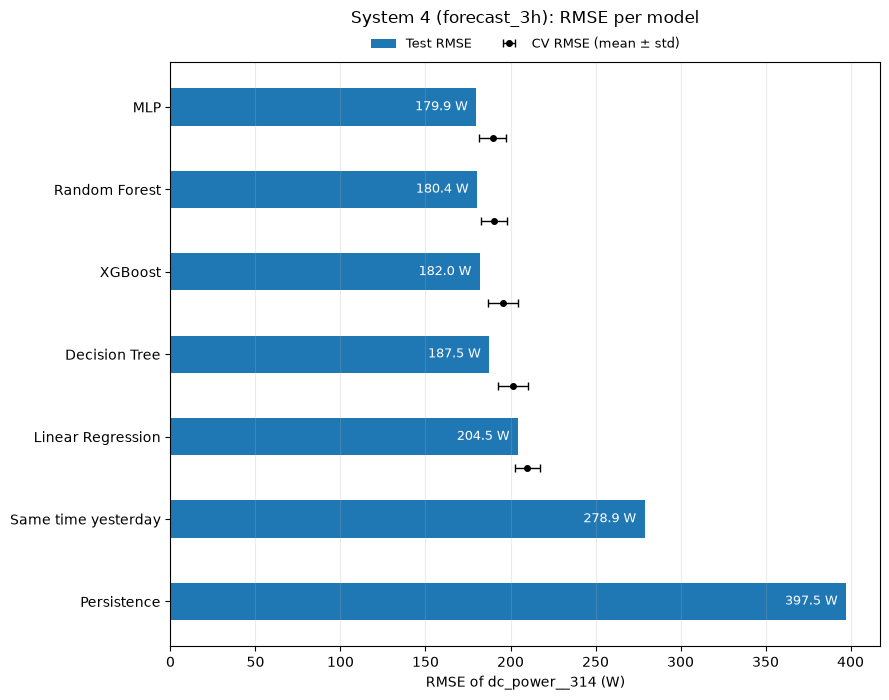

Model metrics saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_forecast_3h_model_metrics.csv
CV folds saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/experiments/system_4_forecast_3h_cv_folds.csv
Test predictions saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/experiments/system_4_forecast_3h_test_predictions.csv
RMSE plot saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_forecast_3h_model_rmse.png


In [25]:
model_metrics = pd.DataFrame(test_results).T.rename_axis("model")
model_metrics["skill_vs_persistence"] = 1 - model_metrics["test_RMSE"] / model_metrics.loc["Persistence", "test_RMSE"]
cv_folds = pd.concat(cv_results, names=["model", None]).reset_index(level="model")
predictions = pd.DataFrame({"y_true": y_test, **test_predictions}, index=y_test.index)

MODEL_METRICS_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_model_metrics.csv"
CV_FOLDS_PATH = EXPERIMENTS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_cv_folds.csv"
PREDICTIONS_PATH = EXPERIMENTS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_test_predictions.csv"
model_metrics.to_csv(MODEL_METRICS_PATH)
cv_folds.to_csv(CV_FOLDS_PATH, index=False)
predictions.to_csv(PREDICTIONS_PATH)

display(model_metrics[["cv_RMSE_mean", "cv_RMSE_std", "test_MAE", "test_RMSE", "test_R2",
                       "skill_vs_persistence", "fit_seconds", "predict_seconds",
                       "model_size_kb"]].round(3))

RMSE_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_model_rmse.png"
order = model_metrics.sort_values("test_RMSE", ascending=False)
positions = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 0.8 * len(order) + 1.5))
ax.barh(positions, order["test_RMSE"], height=0.45, color="tab:blue", label="Test RMSE")
# CV points sit just below each bar so they never cover the bar labels.
ax.errorbar(order["cv_RMSE_mean"], positions - 0.38, xerr=order["cv_RMSE_std"], fmt="o",
            color="black", markersize=4, capsize=3, linewidth=1,
            label="CV RMSE (mean ± std)")
for position, rmse in zip(positions, order["test_RMSE"]):
    ax.annotate(f"{rmse:.1f} W", (rmse, position), xytext=(-6, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9, color="white")
ax.set_yticks(positions, order.index)
ax.set_xlabel(f"RMSE of {TARGET} (W)")
ax.set_title(f"System {SYSTEM_ID} ({CONFIG}): RMSE per model", pad=28)
ax.grid(True, axis="x", alpha=0.25)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(RMSE_PLOT_PATH, dpi=160)
plt.show()

print(f"Model metrics saved to: {MODEL_METRICS_PATH}")
print(f"CV folds saved to: {CV_FOLDS_PATH}")
print(f"Test predictions saved to: {PREDICTIONS_PATH}")
print(f"RMSE plot saved to: {RMSE_PLOT_PATH}")